# Data Modeling

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/processed/telco_customer_churn_clean.csv"
)

print(df.shape)

(7043, 21)


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
### Define the target

df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [3]:
df = df.drop(columns=["customerID"])

In [6]:
features_to_keep = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "MonthlyCharges",
    "TotalCharges"
]

X = df[features_to_keep]
y = df["Churn"]

print("X:", X.shape)
print("y:", y.shape)

X: (7043, 19)
y: (7043,)


In [8]:
### Train/Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\nTraining churn rate:", y_train.mean())
print("Testing churn rate:", y_test.mean())

Training: (5634, 19)
Testing: (1409, 19)

Training churn rate: 0.2653532126375577
Testing churn rate: 0.2654364797728886


## Preprocessing Pipeline

### Identify numerical and categorical columns

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str", "object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### Create the Column Transformer

In [10]:
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

## Logistic Regression

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [12]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [13]:
logistic_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

## Generate Predictions

In [16]:
y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predicted classes:", y_pred[:10])
print("Predicted probabilities:", y_prob[:10])

Predicted classes: [0 1 0 0 0 1 0 0 0 0]
Predicted probabilities: [0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [18]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}")

Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1: 0.6040
ROC-AUC: 0.8421


In [19]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [20]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[926 109]
 [165 209]]


## Confusion Matrix Visualization

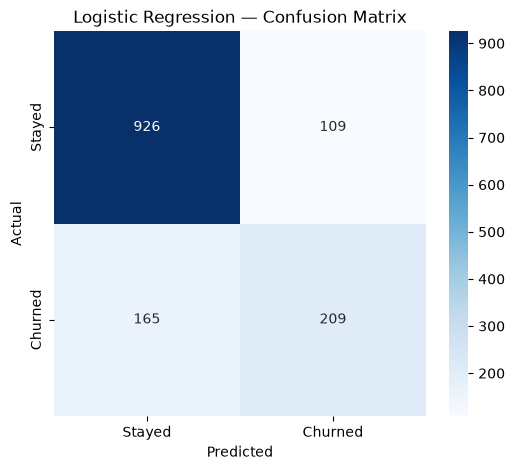

In [26]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## ROC Curve

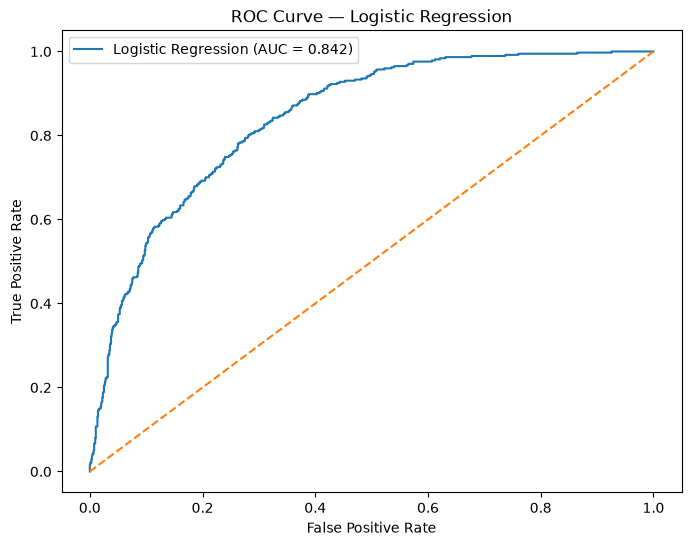

In [27]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression")
plt.legend()

plt.show()

## Precision-Recall Trade-off

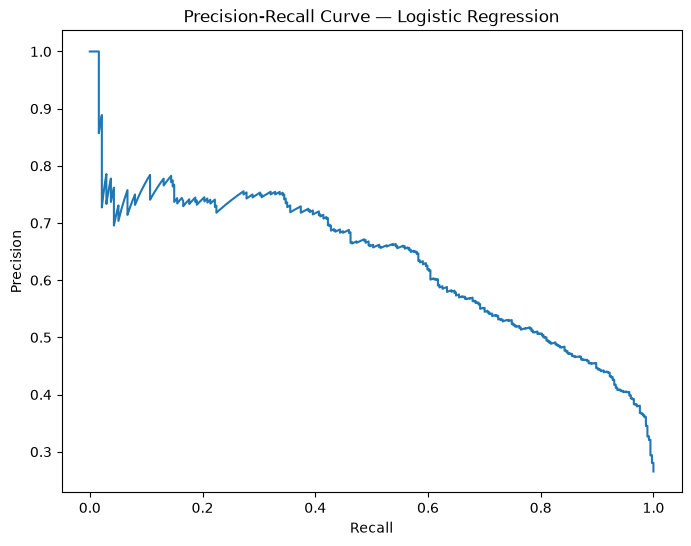

In [28]:
from sklearn.metrics import precision_recall_curve

precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Logistic Regression")

plt.show()

## Random Forest

In [29]:
from sklearn.ensemble import RandomForestClassifier

In [30]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [31]:
random_forest_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [32]:
rf_pred = random_forest_model.predict(X_test)

rf_prob = random_forest_model.predict_proba(
    X_test
)[:, 1]

## Random Forest Evaluation

In [33]:
rf_metrics = {
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_prob)
}

for metric, value in rf_metrics.items():
    print(f"{metric}: {value:.4f}")

Accuracy: 0.7771
Precision: 0.6020
Recall: 0.4733
F1: 0.5299
ROC-AUC: 0.8190


In [34]:
print(
    classification_report(
        y_test,
        rf_pred
    )
)

              precision    recall  f1-score   support

           0       0.82      0.89      0.85      1035
           1       0.60      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.76      0.78      0.77      1409



In [35]:
rf_cm = confusion_matrix(
    y_test,
    rf_pred
)

print(rf_cm)

[[918 117]
 [197 177]]


## Compare the Models

In [36]:
model_comparison = pd.DataFrame({
    "Logistic Regression": metrics,
    "Random Forest": rf_metrics
})

model_comparison.round(4)

,Logistic Regression,Random Forest
Accuracy,0.8055,0.7771
Precision,0.6572,0.6020
Recall,0.5588,0.4733
F1,0.6040,0.5299
ROC-AUC,0.8421,0.8190


## XGBoost

In [37]:
from xgboost import XGBClassifier

In [38]:
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                eval_metric="logloss",
                n_jobs=-1
            )
        )
    ]
)

In [39]:
xgb_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [40]:
xgb_pred = xgb_model.predict(X_test)

xgb_prob = xgb_model.predict_proba(
    X_test
)[:, 1]

In [41]:
print("Predicted classes:", xgb_pred[:10])
print("Predicted probabilities:", xgb_prob[:10])

Predicted classes: [0 1 0 0 0 1 0 0 0 0]
Predicted probabilities: [0.01245682 0.8941344  0.09039524 0.3762519  0.0069608  0.70692796
 0.47967306 0.12871066 0.01065958 0.44929823]


In [42]:
xgb_metrics = {
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "F1": f1_score(y_test, xgb_pred),
    "ROC-AUC": roc_auc_score(y_test, xgb_prob)
}

for metric, value in xgb_metrics.items():
    print(f"{metric}: {value:.4f}")

Accuracy: 0.8041
Precision: 0.6678
Recall: 0.5214
F1: 0.5856
ROC-AUC: 0.8414


In [43]:
xgb_cm = confusion_matrix(
    y_test,
    xgb_pred
)

print(xgb_cm)

[[938  97]
 [179 195]]


In [44]:
print(
    classification_report(
        y_test,
        xgb_pred
    )
)

              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.52      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409



## Three Model Comparison

In [45]:
model_comparison = pd.DataFrame({
    "Logistic Regression": metrics,
    "Random Forest": rf_metrics,
    "XGBoost": xgb_metrics
})

model_comparison.round(4)

,Logistic Regression,Random Forest,XGBoost
Accuracy,0.8055,0.7771,0.8041
Precision,0.6572,0.6020,0.6678
Recall,0.5588,0.4733,0.5214
F1,0.6040,0.5299,0.5856
ROC-AUC,0.8421,0.8190,0.8414


## XGBoost ROC Curve

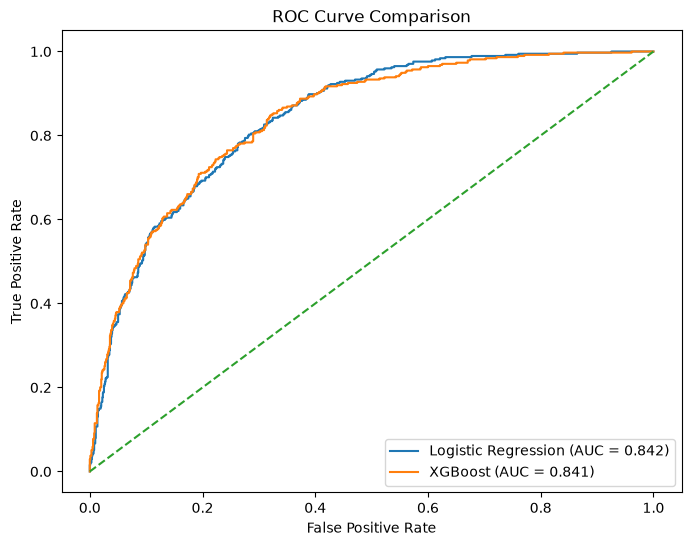

In [46]:
xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {metrics['ROC-AUC']:.3f})"
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost (AUC = {xgb_metrics['ROC-AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()

plt.show()

## Threshold ANalysis

In [47]:
threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.05):
    threshold_pred = (y_prob >= threshold).astype(int)
    
    threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y_test, threshold_pred),
        "recall": recall_score(y_test, threshold_pred),
        "f1": f1_score(y_test, threshold_pred),
        "accuracy": accuracy_score(y_test, threshold_pred)
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results.round(3)

,threshold,precision,recall,f1,accuracy
0,0.20,0.467,0.856,0.604,0.703
1,0.25,0.498,0.810,0.616,0.732
2,0.30,0.519,0.754,0.615,0.749
3,0.35,0.543,0.706,0.614,0.764
4,0.40,0.568,0.668,0.614,0.777
5,0.45,0.602,0.615,0.608,0.790
6,0.50,0.657,0.559,0.604,0.806
7,0.55,0.678,0.463,0.550,0.799
8,0.60,0.718,0.401,0.515,0.799
9,0.65,0.747,0.307,0.436,0.789


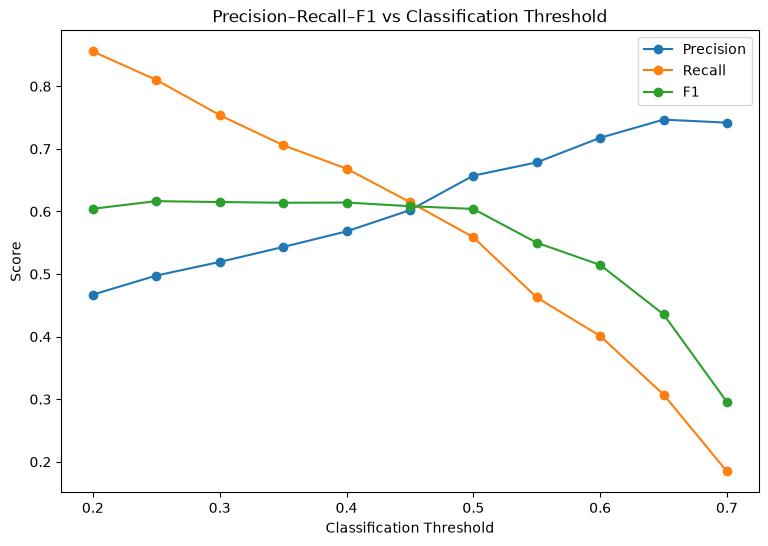

In [48]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision–Recall–F1 vs Classification Threshold")
plt.legend()

plt.show()

## F1-Based Threshold

In [49]:
best_f1_row = threshold_results.loc[
    threshold_results["f1"].idxmax()
]

print(best_f1_row)

threshold    0.250000
precision    0.497537
recall       0.810160
f1           0.616480
accuracy     0.732434
Name: 1, dtype: float64


In [50]:
best_threshold = float(best_f1_row["threshold"])

print("Baseline threshold:", 0.50)
print("Candidate threshold:", best_threshold)

Baseline threshold: 0.5
Candidate threshold: 0.25


In [51]:
candidate_pred = (
    y_prob >= best_threshold
).astype(int)

print(
    classification_report(
        y_test,
        candidate_pred
    )
)

              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1035
           1       0.50      0.81      0.62       374

    accuracy                           0.73      1409
   macro avg       0.70      0.76      0.71      1409
weighted avg       0.80      0.73      0.75      1409



In [52]:
candidate_cm = confusion_matrix(
    y_test,
    candidate_pred
)

print(candidate_cm)

[[729 306]
 [ 71 303]]


## Model Tuning

In [53]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [54]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [55]:
C_values = [0.01, 0.1, 0.5, 1, 2, 5, 10]

cv_results = []

for C in C_values:
    
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                LogisticRegression(
                    C=C,
                    max_iter=1000,
                    random_state=42
                )
            )
        ]
    )
    
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc"
        ],
        n_jobs=-1
    )
    
    cv_results.append({
        "C": C,
        "accuracy": scores["test_accuracy"].mean(),
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f1": scores["test_f1"].mean(),
        "roc_auc": scores["test_roc_auc"].mean()
    })

cv_results = pd.DataFrame(cv_results)

cv_results.round(4)

,C,accuracy,precision,recall,f1,roc_auc
0,0.01,0.8048,0.6746,0.5117,0.5812,0.8435
1,0.10,0.8012,0.6526,0.5378,0.5889,0.8455
2,0.50,0.8026,0.6541,0.5445,0.5936,0.8461
3,1.00,0.8021,0.6529,0.5431,0.5923,0.8462
4,2.00,0.8021,0.6520,0.5452,0.5932,0.8463
5,5.00,0.8033,0.6546,0.5485,0.5963,0.8464
6,10.00,0.8039,0.6557,0.5498,0.5975,0.8464


## Create Train / Validation / Test

In [56]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Train:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nChurn rates:")
print("Train:", y_train_final.mean())
print("Validation:", y_val.mean())
print("Test:", y_test.mean())

Train: (4507, 19)
Validation: (1127, 19)
Test: (1409, 19)

Churn rates:
Train: 0.2653649877967606
Validation: 0.2653061224489796
Test: 0.2654364797728886


### Tune Logistic Regression

In [57]:
C_values = [0.01, 0.1, 0.5, 1, 2, 5, 10]

In [58]:
from sklearn.model_selection import GridSearchCV

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

param_grid = {
    "classifier__C": C_values
}

In [59]:
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(
    X_train_final,
    y_train_final
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of inf

In [60]:
print("Best C:", grid_search.best_params_["classifier__C"])
print("Best CV ROC-AUC:", grid_search.best_score_)

Best C: 10
Best CV ROC-AUC: 0.8438672931072612


In [61]:
val_prob = grid_search.predict_proba(
    X_val
)[:, 1]

In [62]:
val_threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.05):
    val_pred = (
        val_prob >= threshold
    ).astype(int)
    
    val_threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y_val, val_pred),
        "recall": recall_score(y_val, val_pred),
        "f1": f1_score(y_val, val_pred),
        "accuracy": accuracy_score(y_val, val_pred)
    })

val_threshold_results = pd.DataFrame(
    val_threshold_results
)

val_threshold_results.round(3)

,threshold,precision,recall,f1,accuracy
0,0.20,0.468,0.863,0.607,0.704
1,0.25,0.513,0.809,0.628,0.745
2,0.30,0.544,0.759,0.634,0.768
3,0.35,0.579,0.712,0.639,0.786
4,0.40,0.619,0.662,0.640,0.802
5,0.45,0.650,0.595,0.621,0.807
6,0.50,0.699,0.552,0.617,0.818
7,0.55,0.733,0.495,0.591,0.818
8,0.60,0.742,0.375,0.498,0.799
9,0.65,0.766,0.274,0.404,0.785


In [63]:
best_val_threshold_row = val_threshold_results.loc[
    val_threshold_results["f1"].idxmax()
]

print(best_val_threshold_row)

threshold    0.400000
precision    0.618750
recall       0.662207
f1           0.639742
accuracy     0.802130
Name: 4, dtype: float64


In [64]:
final_threshold = float(
    best_val_threshold_row["threshold"]
)

print("Selected threshold:", final_threshold)

Selected threshold: 0.4


## Refit the Final Logistic Regression

In [65]:
X_train_full = pd.concat(
    [X_train_final, X_val]
)

y_train_full = pd.concat(
    [y_train_final, y_val]
)

In [66]:
final_logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                C=grid_search.best_params_["classifier__C"],
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [67]:
final_logistic_model.fit(
    X_train_full,
    y_train_full
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

## Final Test

In [68]:
final_test_prob = final_logistic_model.predict_proba(
    X_test
)[:, 1]

final_test_pred = (
    final_test_prob >= final_threshold
).astype(int)

In [69]:
final_metrics = {
    "Accuracy": accuracy_score(
        y_test,
        final_test_pred
    ),
    "Precision": precision_score(
        y_test,
        final_test_pred
    ),
    "Recall": recall_score(
        y_test,
        final_test_pred
    ),
    "F1": f1_score(
        y_test,
        final_test_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        final_test_prob
    )
}

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

Accuracy: 0.7743
Precision: 0.5636
Recall: 0.6631
F1: 0.6093
ROC-AUC: 0.8412


In [70]:
final_cm = confusion_matrix(
    y_test,
    final_test_pred
)

print(final_cm)

[[843 192]
 [126 248]]


In [71]:
print(
    classification_report(
        y_test,
        final_test_pred
    )
)

              precision    recall  f1-score   support

           0       0.87      0.81      0.84      1035
           1       0.56      0.66      0.61       374

    accuracy                           0.77      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.77      0.78      1409



## Class-Weighted Logistic Regression

In [74]:
class_weight="balanced"

balanced_logistic = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                C=10,
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

balanced_logistic.fit(
    X_train_final,
    y_train_final
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [75]:
balanced_val_prob = balanced_logistic.predict_proba(
    X_val
)[:, 1]

In [76]:
balanced_threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.05):
    pred = (
        balanced_val_prob >= threshold
    ).astype(int)

    balanced_threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y_val, pred),
        "recall": recall_score(y_val, pred),
        "f1": f1_score(y_val, pred),
        "accuracy": accuracy_score(y_val, pred)
    })

balanced_threshold_results = pd.DataFrame(
    balanced_threshold_results
)

balanced_threshold_results.round(3)

,threshold,precision,recall,f1,accuracy
0,0.20,0.382,0.946,0.544,0.579
1,0.25,0.398,0.930,0.558,0.609
2,0.30,0.422,0.920,0.579,0.645
3,0.35,0.438,0.896,0.588,0.667
4,0.40,0.464,0.873,0.606,0.698
5,0.45,0.490,0.819,0.613,0.726
6,0.50,0.519,0.793,0.627,0.750
7,0.55,0.546,0.753,0.633,0.768
8,0.60,0.578,0.716,0.640,0.786
9,0.65,0.624,0.666,0.644,0.805


In [77]:
balanced_best_row = balanced_threshold_results.loc[
    balanced_threshold_results["f1"].idxmax()
]

print(balanced_best_row)

threshold    0.650000
precision    0.623824
recall       0.665552
f1           0.644013
accuracy     0.804791
Name: 9, dtype: float64


In [78]:
balanced_threshold = float(
    balanced_best_row["threshold"]
)

print("Balanced-model threshold:", balanced_threshold)

Balanced-model threshold: 0.65


## Refit on FullTraining Data

In [79]:
final_balanced_logistic = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                C=10,
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

final_balanced_logistic.fit(
    X_train_full,
    y_train_full
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [80]:
balanced_test_prob = final_balanced_logistic.predict_proba(
    X_test
)[:, 1]

balanced_test_pred = (
    balanced_test_prob >= balanced_threshold
).astype(int)

In [81]:
balanced_metrics = {
    "Accuracy": accuracy_score(
        y_test,
        balanced_test_pred
    ),
    "Precision": precision_score(
        y_test,
        balanced_test_pred
    ),
    "Recall": recall_score(
        y_test,
        balanced_test_pred
    ),
    "F1": f1_score(
        y_test,
        balanced_test_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        balanced_test_prob
    )
}

for metric, value in balanced_metrics.items():
    print(f"{metric}: {value:.4f}")

Accuracy: 0.7715
Precision: 0.5591
Recall: 0.6578
F1: 0.6044
ROC-AUC: 0.8406


In [82]:
balanced_cm = confusion_matrix(
    y_test,
    balanced_test_pred
)

print(balanced_cm)

[[841 194]
 [128 246]]


## Tune XGBoost Properly

### Import RandomizedSearchCV

In [83]:
from sklearn.model_selection import RandomizedSearchCV

In [84]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                random_state=42,
                eval_metric="logloss",
                n_jobs=-1
            )
        )
    ]
)

In [85]:
xgb_param_grid = {
    "classifier__n_estimators": [200, 300, 400, 500],
    "classifier__max_depth": [2, 3, 4, 5],
    "classifier__learning_rate": [0.02, 0.05, 0.08, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5]
}

In [86]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

xgb_search.fit(
    X_train_final,
    y_train_final
)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': [0.7, 0.8, ...], 'classifier__learning_rate': [0.02, 0.05, ...], 'classifier__max_depth': [2, 3, ...], 'classifier__min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than m

In [87]:
print("Best parameters:")
print(xgb_search.best_params_)

print("\nBest CV ROC-AUC:")
print(xgb_search.best_score_)

Best parameters:
{'classifier__subsample': 0.8, 'classifier__n_estimators': 200, 'classifier__min_child_weight': 1, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.02, 'classifier__colsample_bytree': 0.8}

Best CV ROC-AUC:
0.8459237952028958


In [88]:
tuned_xgb_val_prob = xgb_search.predict_proba(
    X_val
)[:, 1]

In [89]:
tuned_xgb_threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.05):
    pred = (
        tuned_xgb_val_prob >= threshold
    ).astype(int)

    tuned_xgb_threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y_val, pred),
        "recall": recall_score(y_val, pred),
        "f1": f1_score(y_val, pred),
        "accuracy": accuracy_score(y_val, pred)
    })

tuned_xgb_threshold_results = pd.DataFrame(
    tuned_xgb_threshold_results
)

tuned_xgb_threshold_results.round(3)

,threshold,precision,recall,f1,accuracy
0,0.20,0.466,0.839,0.599,0.702
1,0.25,0.504,0.813,0.622,0.738
2,0.30,0.528,0.779,0.630,0.757
3,0.35,0.578,0.729,0.645,0.787
4,0.40,0.617,0.669,0.642,0.802
5,0.45,0.681,0.572,0.622,0.815
6,0.50,0.719,0.472,0.570,0.811
7,0.55,0.741,0.344,0.470,0.794
8,0.60,0.768,0.254,0.382,0.782
9,0.65,0.881,0.197,0.322,0.780


In [90]:
tuned_xgb_best_row = tuned_xgb_threshold_results.loc[
    tuned_xgb_threshold_results["f1"].idxmax()
]

print(tuned_xgb_best_row)

threshold    0.350000
precision    0.578249
recall       0.729097
f1           0.644970
accuracy     0.787045
Name: 3, dtype: float64


In [91]:
tuned_xgb_threshold = float(
    tuned_xgb_best_row["threshold"]
)

print(
    "Selected XGBoost threshold:",
    tuned_xgb_threshold
)

Selected XGBoost threshold: 0.35


## Refit Tuned XGBoost

In [93]:
final_xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                **{
                    key.replace("classifier__", ""): value
                    for key, value in xgb_search.best_params_.items()
                },
                random_state=42,
                eval_metric="logloss",
                n_jobs=-1
            )
        )
    ]
)

final_xgb_model.fit(
    X_train_full,
    y_train_full
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [94]:
## Final XGBoost Test

final_xgb_test_prob = final_xgb_model.predict_proba(
    X_test
)[:, 1]

final_xgb_test_pred = (
    final_xgb_test_prob >= tuned_xgb_threshold
).astype(int)

In [95]:
final_xgb_metrics = {
    "Accuracy": accuracy_score(
        y_test,
        final_xgb_test_pred
    ),
    "Precision": precision_score(
        y_test,
        final_xgb_test_pred
    ),
    "Recall": recall_score(
        y_test,
        final_xgb_test_pred
    ),
    "F1": f1_score(
        y_test,
        final_xgb_test_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        final_xgb_test_prob
    )
}

for metric, value in final_xgb_metrics.items():
    print(f"{metric}: {value:.4f}")

Accuracy: 0.7757
Precision: 0.5604
Recall: 0.7193
F1: 0.6300
ROC-AUC: 0.8429


In [96]:
final_xgb_cm = confusion_matrix(
    y_test,
    final_xgb_test_pred
)

print(final_xgb_cm)

[[824 211]
 [105 269]]


## Final Model Comparison

In [97]:
final_model_comparison = pd.DataFrame({
    "Standard Logistic Regression": final_metrics,
    "Balanced Logistic Regression": balanced_metrics,
    "Tuned XGBoost": final_xgb_metrics
})

final_model_comparison.round(4)

,Standard Logistic Regression,Balanced Logistic Regression,Tuned XGBoost
Accuracy,0.7743,0.7715,0.7757
Precision,0.5636,0.5591,0.5604
Recall,0.6631,0.6578,0.7193
F1,0.6093,0.6044,0.6300
ROC-AUC,0.8412,0.8406,0.8429


In [98]:
final_model_comparison.to_csv(
    "../reports/model_results.csv"
)

In [99]:
threshold_summary = pd.DataFrame({
    "model": [
        "Standard Logistic Regression",
        "Balanced Logistic Regression",
        "Tuned XGBoost"
    ],
    "threshold": [
        final_threshold,
        balanced_threshold,
        tuned_xgb_threshold
    ]
})

threshold_summary

,model,threshold
0,Standard Logistic Regression,0.40
1,Balanced Logistic Regression,0.65
2,Tuned XGBoost,0.35


In [100]:
threshold_summary.to_csv(
    "../reports/model_thresholds.csv",
    index=False
)

# Prepare SHAP

In [101]:
import shap

/Users/dhruvsingh/Downloads/Projects/Customer Churn Prediction & Retention Intelligence/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [102]:
fitted_preprocessor = final_xgb_model.named_steps[
    "preprocessor"
]

fitted_xgb = final_xgb_model.named_steps[
    "classifier"
]

In [103]:
X_test_transformed = fitted_preprocessor.transform(
    X_test
)

print(X_test_transformed.shape)

(1409, 45)


## Feature Names

In [104]:
feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

print("Number of model features:", len(feature_names))
print(feature_names[:30])

Number of model features: 45
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Female' 'cat__gender_Male'
 'cat__Partner_No' 'cat__Partner_Yes' 'cat__Dependents_No'
 'cat__Dependents_Yes' 'cat__PhoneService_No' 'cat__PhoneService_Yes'
 'cat__MultipleLines_No' 'cat__MultipleLines_No phone service'
 'cat__MultipleLines_Yes' 'cat__InternetService_DSL'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No' 'cat__OnlineSecurity_No internet service'
 'cat__OnlineSecurity_Yes' 'cat__OnlineBackup_No'
 'cat__OnlineBackup_No internet service' 'cat__OnlineBackup_Yes'
 'cat__DeviceProtection_No' 'cat__DeviceProtection_No internet service'
 'cat__DeviceProtection_Yes' 'cat__TechSupport_No'
 'cat__TechSupport_No internet service' 'cat__TechSupport_Yes']


## SHAP Explainer

In [107]:
explainer = shap.TreeExplainer(
    fitted_xgb
)

shap_values = explainer.shap_values(
    X_test_transformed
)

print(type(shap_values))
print(shap_values.shape)

<class 'numpy.ndarray'>
(1409, 45)


## Global Feature Importance

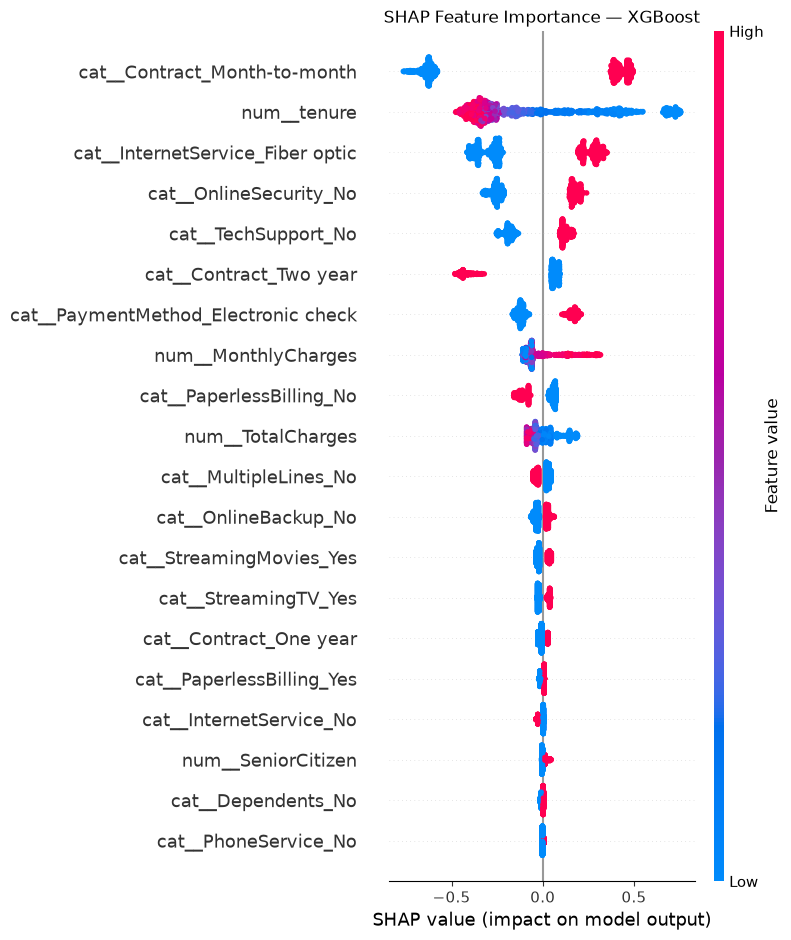

In [108]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    show=False
)

plt.title("SHAP Feature Importance — XGBoost")
plt.tight_layout()
plt.show()

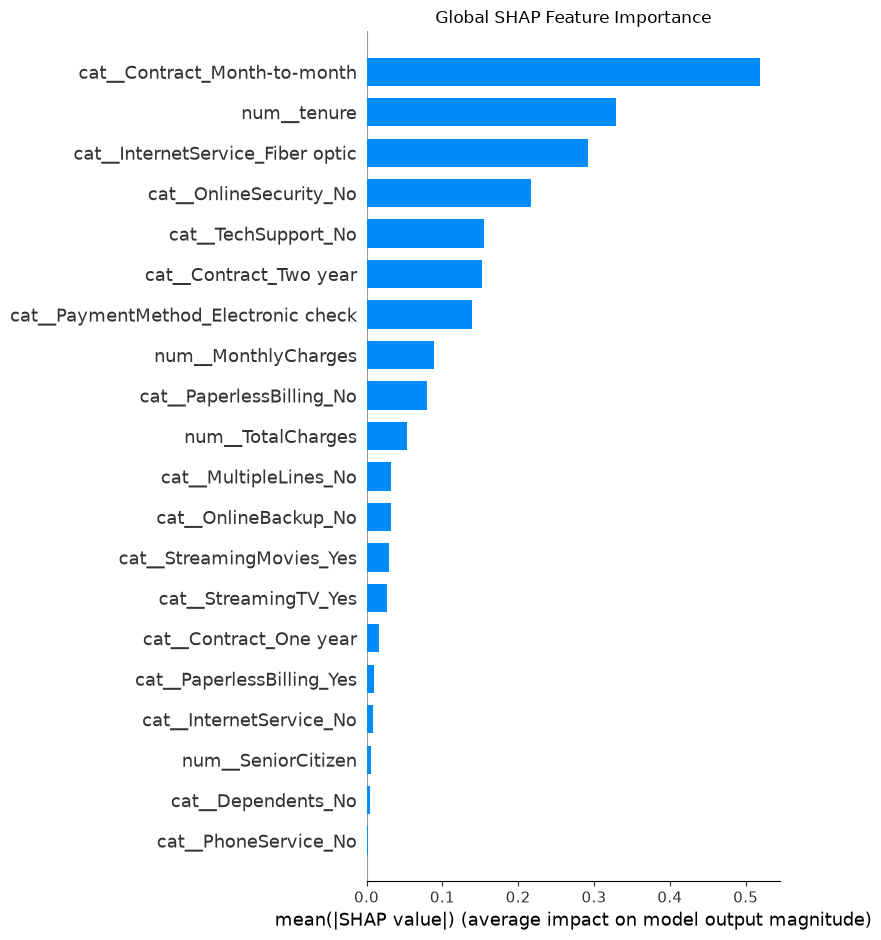

In [109]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title("Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

In [114]:
customer_indices = [0, 1, 2]

for idx in customer_indices:
    print(f"\n{'='*60}")
    print(f"Customer index: {idx}")
    print(f"{'='*60}")

    prediction_probability = final_xgb_model.predict_proba(
        X_test.iloc[[idx]]
    )[0, 1]

    prediction = int(
        prediction_probability >= tuned_xgb_threshold
    )

    print(f"Churn probability: {prediction_probability:.2%}")
    print(f"Predicted churn: {'Yes' if prediction == 1 else 'No'}")
    print(f"Actual churn: {'Yes' if y_test.iloc[idx] == 1 else 'No'}")


Customer index: 0
Churn probability: 7.12%
Predicted churn: No
Actual churn: No

Customer index: 1
Churn probability: 57.64%
Predicted churn: Yes
Actual churn: No

Customer index: 2
Churn probability: 8.52%
Predicted churn: No
Actual churn: No


### Customer 1 flag

In [115]:
idx = 1

customer_shap = shap_values[idx]

shap_df = pd.DataFrame({
    "feature": feature_names,
    "shap_value": customer_shap
})

shap_df["absolute_shap"] = shap_df["shap_value"].abs()

shap_df = shap_df.sort_values(
    "absolute_shap",
    ascending=False
)

print("Top factors influencing this customer's prediction:")
print(shap_df.head(10).to_string(index=False))

Top factors influencing this customer's prediction:
                            feature  shap_value  absolute_shap
       cat__Contract_Month-to-month    0.410033       0.410033
   cat__InternetService_Fiber optic    0.343714       0.343714
                        num__tenure    0.228840       0.228840
             cat__OnlineSecurity_No    0.200418       0.200418
                cat__TechSupport_No   -0.185586       0.185586
                num__MonthlyCharges    0.160304       0.160304
cat__PaymentMethod_Electronic check   -0.148175       0.148175
             cat__Contract_Two year    0.070502       0.070502
           cat__PaperlessBilling_No    0.061576       0.061576
                  num__TotalCharges    0.042425       0.042425


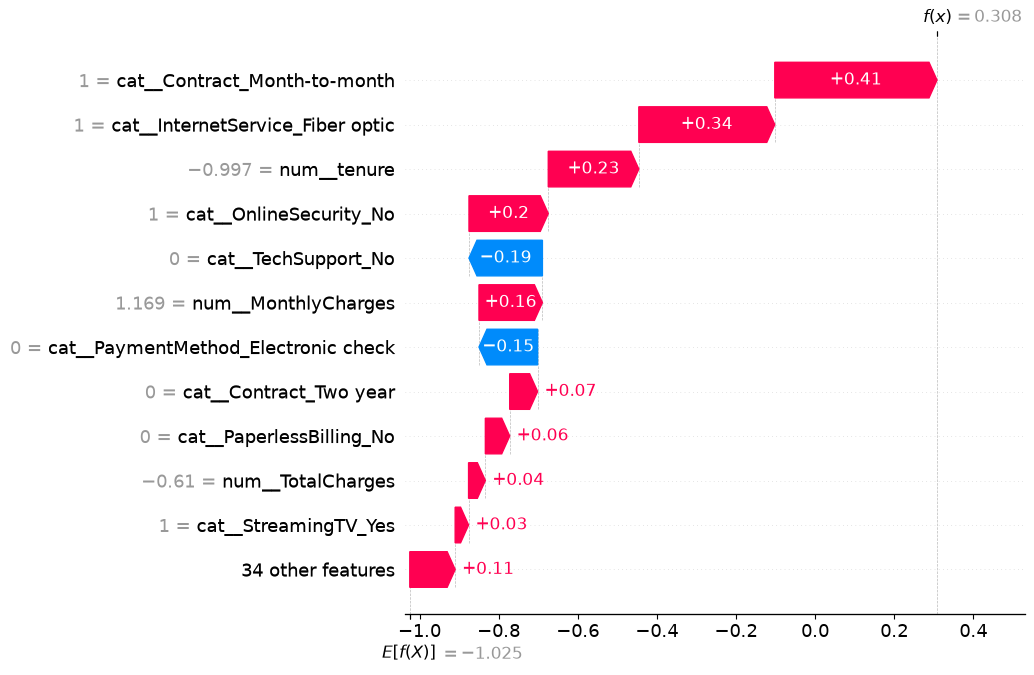

In [116]:
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[idx],
        base_values=explainer.expected_value,
        data=X_test_transformed[idx].toarray().flatten()
            if hasattr(X_test_transformed[idx], "toarray")
            else X_test_transformed[idx],
        feature_names=feature_names
    ),
    max_display=12
)

### Retention Intelligence Table

In [118]:
# Generate churn probabilities for the complete test set

test_probabilities = final_xgb_model.predict_proba(X_test)[:, 1]

retention_df = X_test.copy()

retention_df["actual_churn"] = y_test.values
retention_df["churn_probability"] = test_probabilities

retention_df["predicted_churn"] = (
    retention_df["churn_probability"] >= tuned_xgb_threshold
).astype(int)

retention_df["risk_segment"] = pd.cut(
    retention_df["churn_probability"],
    bins=[-0.01, 0.35, 0.60, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print(retention_df.head())

      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
437     Male              0     Yes        Yes      72          Yes   
2280  Female              1      No         No       8          Yes   
2235  Female              0     Yes        Yes      41          Yes   
4460    Male              0     Yes         No      18          Yes   
3761  Female              0     Yes         No      72          Yes   

     MultipleLines InternetService OnlineSecurity OnlineBackup  ...  \
437            Yes     Fiber optic            Yes          Yes  ...   
2280           Yes     Fiber optic             No           No  ...   
2235           Yes             DSL            Yes          Yes  ...   
4460            No     Fiber optic             No           No  ...   
3761           Yes             DSL            Yes          Yes  ...   

     StreamingMovies        Contract PaperlessBilling  \
437              Yes        Two year              Yes   
2280             Yes  Month-to-m

In [119]:
print(
    retention_df["risk_segment"]
    .value_counts()
    .sort_index()
)

risk_segment
Low Risk       929
Medium Risk    336
High Risk      144
Name: count, dtype: int64


In [120]:
print(
    retention_df.groupby("risk_segment", observed=True)["churn_probability"]
    .agg(["count", "mean", "min", "max"])
)

              count      mean       min       max
risk_segment                                     
Low Risk        929  0.127832  0.025409  0.349506
Medium Risk     336  0.468521  0.350200  0.597666
High Risk       144  0.689541  0.602265  0.810733


In [121]:
risk_summary = (
    retention_df
    .groupby("risk_segment", observed=True)
    .agg(
        customers=("actual_churn", "size"),
        actual_churners=("actual_churn", "sum"),
        avg_churn_probability=("churn_probability", "mean")
    )
)

risk_summary["actual_churn_rate"] = (
    risk_summary["actual_churners"]
    / risk_summary["customers"]
)

print(risk_summary)

              customers  actual_churners  avg_churn_probability  \
risk_segment                                                      
Low Risk            929              105               0.127832   
Medium Risk         336              163               0.468521   
High Risk           144              106               0.689541   

              actual_churn_rate  
risk_segment                     
Low Risk               0.113025  
Medium Risk            0.485119  
High Risk              0.736111  


In [122]:
print(
    retention_df.groupby("risk_segment", observed=True)["churn_probability"]
    .describe()
)

              count      mean       std       min       25%       50%  \
risk_segment                                                            
Low Risk      929.0  0.127832  0.092778  0.025409  0.051770  0.099682   
Medium Risk   336.0  0.468521  0.069693  0.350200  0.410000  0.466606   
High Risk     144.0  0.689541  0.054277  0.602265  0.643909  0.693531   

                   75%       max  
risk_segment                      
Low Risk      0.188730  0.349506  
Medium Risk   0.521561  0.597666  
High Risk     0.730172  0.810733  


### retention action framework

In [124]:
def retention_action(row):

    if row["risk_segment"] == "High Risk":

        if (
            row["Contract"] == "Month-to-month"
            and row["TechSupport"] == "No"
            and row["OnlineSecurity"] == "No"
        ):
            return "Priority: support + security + contract retention"

        elif row["Contract"] == "Month-to-month":
            return "Priority: contract retention offer"

        elif row["TechSupport"] == "No":
            return "Priority: proactive support outreach"

        elif row["MonthlyCharges"] >= retention_df["MonthlyCharges"].median():
            return "Priority: high-value retention review"

        else:
            return "Priority: retention outreach"

    elif row["risk_segment"] == "Medium Risk":

        if (
            row["Contract"] == "Month-to-month"
            and row["MonthlyCharges"] >= retention_df["MonthlyCharges"].median()
        ):
            return "Contract upgrade + value review"

        elif row["TechSupport"] == "No":
            return "Proactive support outreach"

        elif row["OnlineSecurity"] == "No":
            return "Security engagement"

        else:
            return "Engagement campaign"

    else:
        return "Standard engagement"


retention_df["retention_action"] = retention_df.apply(
    retention_action,
    axis=1
)

print(
    retention_df["retention_action"]
    .value_counts()
)

retention_action
Standard engagement                                  929
Contract upgrade + value review                      236
Priority: support + security + contract retention    140
Proactive support outreach                            86
Security engagement                                   13
Priority: contract retention offer                     4
Engagement campaign                                    1
Name: count, dtype: int64


### Quantidy oppurunity

In [125]:
action_summary = (
    retention_df
    .groupby("retention_action", sort=False)
    .agg(
        customers=("actual_churn", "size"),
        actual_churners=("actual_churn", "sum"),
        avg_churn_probability=("churn_probability", "mean"),
        monthly_revenue=("MonthlyCharges", "sum")
    )
)

action_summary["actual_churn_rate"] = (
    action_summary["actual_churners"]
    / action_summary["customers"]
)

action_summary = action_summary.sort_values(
    "avg_churn_probability",
    ascending=False
)

print(action_summary)

                                                   customers  actual_churners  \
retention_action                                                                
Priority: support + security + contract retention        140              103   
Priority: contract retention offer                         4                3   
Contract upgrade + value review                          236              112   
Proactive support outreach                                86               42   
Security engagement                                       13                8   
Engagement campaign                                        1                1   
Standard engagement                                      929              105   

                                                   avg_churn_probability  \
retention_action                                                           
Priority: support + security + contract retention               0.690439   
Priority: contract retention offer        

In [126]:
retention_df.to_csv(
    "../reports/customer_retention_scores.csv",
    index=False
)

action_summary.to_csv(
    "../reports/retention_action_summary.csv"
)

risk_summary.to_csv(
    "../reports/risk_segment_summary.csv"
)

print("Retention intelligence reports saved successfully.")

Retention intelligence reports saved successfully.


In [127]:
import os

for file in [
    "../reports/customer_retention_scores.csv",
    "../reports/retention_action_summary.csv",
    "../reports/risk_segment_summary.csv"
]:
    print(file, "->", os.path.getsize(file), "bytes")

../reports/customer_retention_scores.csv -> 245539 bytes
../reports/retention_action_summary.csv -> 577 bytes
../reports/risk_segment_summary.csv -> 224 bytes


# Streamlit

In [128]:
import joblib
import os

model_path = "../models/final_xgb_model.pkl"

joblib.dump(
    final_xgb_model,
    model_path
)

print("Model saved to:", os.path.abspath(model_path))

Model saved to: /Users/dhruvsingh/Downloads/Projects/Customer Churn Prediction & Retention Intelligence/models/final_xgb_model.pkl


In [129]:
import os

print(
    "Model exists:",
    os.path.exists("../models/final_xgb_model.pkl")
)

print(
    "Model size:",
    os.path.getsize("../models/final_xgb_model.pkl"),
    "bytes"
)

Model exists: True
Model size: 196732 bytes


In [130]:
import json

threshold_path = "../models/model_threshold.json"

with open(threshold_path, "w") as f:
    json.dump(
        {
            "model": "Tuned XGBoost",
            "threshold": float(tuned_xgb_threshold)
        },
        f,
        indent=4
    )

print("Threshold saved to:", os.path.abspath(threshold_path))

Threshold saved to: /Users/dhruvsingh/Downloads/Projects/Customer Churn Prediction & Retention Intelligence/models/model_threshold.json
